# San Francisco — NTN RT Urban Sweep (TR 38.811 cross-check)

Runs the site-specific ray-tracing pipeline over Sionna's built-in
`san_francisco` scene, as an **NTN-Urban** counterpart to the Suburban (UW campus)
and Dense Urban (Canary Wharf) runs.

**Why this scene.** Geometric LoS probability against elevation, averaged over 8
azimuths on a 90×90 receiver grid, matches the TR 38.811 **Urban** table
(Table 6.6.1-1) to a mean absolute error of **0.025** — roughly five times closer
than any other Sionna built-in:

| | 10° | 20° | 30° | 40° | 50° | 60° | 70° | 80° | mean \|Δ\| |
|---|---|---|---|---|---|---|---|---|---|
| TR 38.811 Urban | .246 | .386 | .493 | .613 | .726 | .805 | .919 | .968 | — |
| **san_francisco** | .228 | .383 | .512 | .616 | .704 | .779 | .847 | .917 | **0.025** |
| munich | .535 | .643 | .713 | .768 | .819 | .867 | .913 | .957 | 0.122 |
| florence | .538 | .654 | .713 | .757 | .798 | .840 | .888 | .939 | 0.122 |
| etoile | .540 | .688 | .771 | .824 | .864 | .899 | .934 | .967 | 0.149 |

Munich and etoile are in fact closer to TR 38.811 **Suburban** on this metric, so
the intuitive pick would have been the wrong one. The San Francisco match is
produced by the building stock rather than by the hills (buildings-only variant
0.024, terrain-only 0.300) and is stable under grid refinement, azimuth rotation
and edge-margin exclusion.

**Two things differ from the Wharf notebook**, both consequences of the scene:

1. It has **104 m of terrain relief**, so receiver placement uses the
   terrain-aware two-scene occupancy grid and a bare-earth companion scene that
   cell 6 generates.
2. It has **4735 shapes**, which the per-shape solver dispatch cannot handle —
   hence `MERGE_SHAPES = True` and the corresponding `scene_utils` key.

Run this notebook **twice**: `FREQUENCY = 2e9`, then `20e9`.


## 1 - Environment Setup

In [1]:
import os, sys

# DrJIT / LLVM path
# NOTE: previously followed by `%env DRJIT_LIBLLVM_PATH="..."` -- removed.
# IPython's %env magic does not strip quotes from the value, so that line
# was setting os.environ['DRJIT_LIBLLVM_PATH'] to the literal string
# '"/usr/lib/x86_64-linux-gnu/libLLVM-20.so"' (quote characters included).
# Harmless for drjit in this kernel (already initialized on the line above,
# using the correct unquoted value) but fatal for any subprocess launched
# later (Section 6) that inherits this corrupted value via env=os.environ
# and tries to load DrJIT/LLVM fresh.
os.environ['DRJIT_LIBLLVM_PATH'] = '/usr/lib/x86_64-linux-gnu/libLLVM-20.so'
import drjit as drjit

# Add script directory to path so helper modules can be imported
SCRIPT_DIR = os.path.abspath(".")
sys.path.insert(0, SCRIPT_DIR)


print("Environment configured.")

Environment configured.


## 2 - Imports

In [2]:
import json
import time
import pickle
import subprocess
import numpy as np
from scipy import constants
%matplotlib inline
import matplotlib.pyplot as plt

# Sionna / DrJIT / Mitsuba are imported for their backend setup and, unlike the
# Wharf and Sieg notebooks, BY NAME: cell 6 reads sionna.rt.scene.san_francisco
# (the packaged scene's absolute path) and loads the scene once to prove the
# material names resolve; cell 15 casts verification rays with mitsuba directly.
#
# TRAP, and it is the inverse of the one build_occupancy_grid documents:
# importing sionna.rt sets the global Mitsuba variant to a radio variant.
# san_francisco.xml declares its BSDFs as <bsdf type="itu-radio-material">, a
# plugin registered ONLY under those variants, so
#     mi.load_file(SCENE_XML)  under "cuda_ad_rgb" or "llvm_ad_rgb"
#     -> RuntimeError: Plugin "itu-radio-material" not found!
# build_occupancy_grid_terrain defaults to cuda_ad_rgb and falls back to
# llvm_ad_rgb, so cell 15 MUST pass variant=GRID_VARIANT explicitly. Wharf and
# Sieg never hit this: their XMLs declare plain diffuse/twosided BSDFs.
import sionna
import sionna.rt
import drjit
import mitsuba as mi

# Local helpers.
#
# build_occupancy_grid (the FLAT-ground one) is deliberately not imported: its
# test is `hit_z <= rx_height + building_thresh`, valid only for ground at z ~ 0.
# mesh-Terrain here spans z = 0..104 m, so it would call most of the city a
# building and bury every receiver inside a hillside.
# build_occupancy_grid_xml is not imported either -- it needs <transform><matrix>
# footprints and this scene has zero <transform> elements.
from channel_utils    import tx_position_from_elevation, elevation_summary
from scene_utils      import (build_occupancy_grid_terrain,
                              sample_rx_positions, save_rx_positions, load_rx_positions)
from checkpoint_utils import simulation_status
from plot_utils       import plot_rx_positions

from atmospheric_utils import atmospheric_deterministic_summary
from ionospheric_utils import ionospheric_summary
from fetch_vtec        import vtec_for_pipeline
from fetch_tle         import fetch_tle_catalog

from orbital_utils import (
        make_reference_satrec, find_pass,
        find_pass_with_geometry_class, REFERENCE_LEO_ALTITUDES_KM,
        generate_waypoints, parse_tle_catalog, parse_tle_text,
        search_tle_catalog_for_pass, best_pass_in_catalog,
    )
from sgp4.api import jday

print("All imports OK.")


All imports OK.


## 3 - Global Parameters

> **Update the values in this cell before running.**  
> Every simulation knob is exposed here.

In [11]:
# ─── SCENE (Sionna built-in San Francisco, TR 38.811 NTN-Urban proxy) ────────
# Used AS AUTHORED. Unlike Wharf (rebuilt into three physical roles) and Sieg
# (vegetation stripped, ground materials made frequency-valid), nothing here
# needs rewriting: 4735 shapes, zero <transform> elements, three BSDFs, all
# valid across 1-60 / 1-100 GHz, so both carriers load without
# itu_range_patch.widen(). Material physics is re-bound at runtime through
# MATERIAL_PARAMS instead, so site-packages is never touched.
SCENE_XML   = sionna.rt.scene.san_francisco     # absolute path into site-packages
SF_MESH_DIR = os.path.join(os.path.dirname(SCENE_XML), "meshes")

# Measured bbox: x [-508.16, 713.55], y [-468.03, 459.66], z [0, 170.63]
#   -> extent 1221.7 x 927.7 x 170.6 m
SCENE_CENTER      = [102.70, -4.19]   # [x, y] bbox centre [m]  -- NOT [0, 0]
SCENE_RADIUS_TRUE = 767.0             # [m] true horizontal half-diagonal

# SCENE_RADIUS sizes the TX beam half-angle, arctan(SCENE_RADIUS / slant),
# recomputed per elevation inside run_elevation_sim.py. Receivers here are
# terrain-following and span z = 0..105 m while tx.look_at() aims at z = 0, so
# the worst-corner offset from the beam axis is sqrt(767^2 + 105^2) = 774 m --
# just outside a 767 m cone. 800 m gives 4.3% margin and costs nothing.
SCENE_RADIUS      = 800.0

# ── Bare-earth companion scene ───────────────────────────────────────────────
# mesh-Terrain (meshes/Terrain.ply, 192k faces) spans z = 0..104.00 m: this
# scene has real topography, so build_occupancy_grid_terrain needs a bare-earth
# scene to difference against and Sionna ships none. Written here as a strict
# two-element subset of the parent -- same PLY, same BSDF declaration --
# referenced IN PLACE by absolute path, so no mesh is copied. (Sieg's
# equivalent uses a relative meshes/ path and so must sit beside the mesh
# folder; that is the one structural difference.)
GROUND_XML = os.path.join(SCRIPT_DIR, "san_francisco_ground_only.xml")

_GROUND_XML_TEXT = f"""<scene version="2.1.0">

<!-- Bare-earth companion to Sionna's built-in san_francisco scene.
     Generated by site_simulation_sf.ipynb, cell 6. Geometry only: it exists so
     scene_utils.build_occupancy_grid_terrain can cast the SAME downward ray set
     into the full scene and into bare earth and classify each cell on the
     DIFFERENCE (top_z - ground_z), which is relief-invariant. mesh-Terrain
     spans z = 0..104 m, so no absolute height test can work here.
     Source: {SCENE_XML} -->

    <bsdf type="itu-radio-material" id="mat-terrain">
        <string name="type" value="concrete"/>
        <float name="thickness" value="0.1"/>
    </bsdf>

    <shape type="ply" id="mesh-Terrain" name="mesh-Terrain">
        <string name="filename" value="{SF_MESH_DIR}/Terrain.ply"/>
        <ref id="mat-terrain" name="bsdf"/>
    </shape>

</scene>
"""

_prev = open(GROUND_XML).read() if os.path.exists(GROUND_XML) else None
if _prev != _GROUND_XML_TEXT:
    with open(GROUND_XML, "w") as _fh:
        _fh.write(_GROUND_XML_TEXT)
    print(f"Wrote bare-earth companion scene -> {GROUND_XML}")
else:
    print(f"Bare-earth companion scene up to date -> {GROUND_XML}")
assert os.path.exists(os.path.join(SF_MESH_DIR, "Terrain.ply")), \
    f"Terrain.ply missing under {SF_MESH_DIR} -- did the sionna install move?"

# Mitsuba variant for both ray-cast scenes in cell 15. NOT the function's
# default "cuda_ad_rgb" and NOT its "llvm_ad_rgb" fallback -- neither can
# instantiate an itu-radio-material BSDF. CPU users want
# "llvm_ad_mono_polarized".
GRID_VARIANT = "cuda_ad_mono_polarized"

# ── Scene location & simulation date ────────────────────────────────────────
SIM_LAT             =  37.8005     # North Beach / Telegraph Hill, San Francisco
SIM_LON             = -122.4105
SIM_DATE            = "2026-06-15"


# ─── RF ───────────────────────────────────────────────────────────────────────
# RUN THIS NOTEBOOK TWICE: 2e9, then 20e9 -- the only like-for-like carriers
# against TR 38.811's S-band and Ka tables. ns-3's band selector is a hard
# threshold at 13 GHz, so anything in the 3-13 GHz gap is scored against
# 2 GHz-measured values and validate_3gpp tags it "off-band".
FREQUENCY       = 20e9         # Carrier frequency [Hz]   <- then re-run with 20e9
TX_POWER_DBM    = 74.0        # TX transmit power [dBm]
RX_HEIGHT       = 1.5         # Receiver height ABOVE LOCAL GROUND [m]

# ─── MATERIALS (ITU-R P.2040-1, re-bound at runtime) ─────────────────────────
# Keys are the ids scene.get() actually resolves. Sionna's process_xml strips a
# leading "mat-", so the three BSDFs (marble / metal / mat-terrain) resolve as
# "marble", "metal", "terrain"; scene.get("mat-terrain") returns None.
#
# a,b,c,d set eps_r = a*f_GHz**b and sigma = c*f_GHz**d, applied by
# build_scene_batch AFTER scene.frequency fires the ITU callback, so they
# override the XML's ITU identity unconditionally. That is how the physics is
# corrected without rewriting the scene.
#
# The geometry, not the names, decides the role. Measured over 300 random
# meshes of each kind:
#   metal  ("-roof", 2367 shapes) -> 3091/3091 faces up-facing, 0 vertical,
#                                    median mesh thickness 0.00 m: flat caps.
#   marble ("-wall", 2367 shapes) -> 7142/7142 faces vertical, 0 up-facing.
# So "metal" is roofs, as in Canary Wharf, and left as ITU metal (sigma = 1e7)
# all 2367 rooftops would be perfect reflectors -- at MAX_DEPTH = 3 the
# roof->facade->UE double bounce then becomes an artificially strong NLoS
# contributor, suppressing K exactly where it is being compared against
# TR 38.811. build_wharf_du_scene remapped roofs for this reason; the same
# coefficients are used here so the two site runs and the PPP ensemble differ
# in GEOMETRY ONLY.
#
# Ground keeps the author's concrete (valid 1-100 GHz), so unlike the Wharf run
# -- whose itu_medium_dry_ground is measured only to 10 GHz -- no surface here
# is frequency-extrapolated at 20 GHz.
#
# TRAP: scattering_coefficient defaults to 0. Every entry must set it or
# diffuse scattering silently vanishes for that surface.
MATERIAL_PARAMS  = {
    "marble":  {"a": 5.24, "b": 0.0, "c": 0.0462, "d": 0.7822,   # facades -> ITU concrete
                "scattering_coefficient": 0.40, "xpd_coefficient": 0.0},
    "metal":   {"a": 3.91, "b": 0.0, "c": 0.0238, "d": 0.16,     # roofs   -> ITU brick, not PEC
                "scattering_coefficient": 0.50, "xpd_coefficient": 0.0},
    "terrain": {"a": 5.24, "b": 0.0, "c": 0.0462, "d": 0.7822,   # ground  -> ITU concrete
                "scattering_coefficient": 0.30, "xpd_coefficient": 0.0},
}
MATERIAL_NAMES   = list(MATERIAL_PARAMS)
SCATTERING_COEFF = MATERIAL_PARAMS["marble"]["scattering_coefficient"]
ETA_R            = 5.24        # legacy cfg keys; not used by the simulation
SIGMA            = 0.0462

# ── Silent-material-mismatch guard ───────────────────────────────────────────
# build_scene_batch does `mat = scene.get(n); if mat is None: continue` twice,
# with no warning. One wrong key and the whole sweep completes with that
# surface's scattering_coefficient left at 0 and its permittivity at the stock
# ITU value -- diffuse scattering silently gone, nothing in the logs. Resolve
# the names once, here, and fail loudly.
_probe   = sionna.rt.load_scene(SCENE_XML, merge_shapes=True)
_missing = [m for m in MATERIAL_NAMES if _probe.get(m) is None]
if _missing:
    raise KeyError(
        f"scene.get() returns None for {_missing} in {SCENE_XML}. "
        f"build_scene_batch would skip them SILENTLY. Resolvable names: "
        f"{sorted(_probe.radio_materials)}")
print("Materials resolved: " + "  ".join(
    f"{m}->{type(_probe.get(m)).__name__}" for m in MATERIAL_NAMES))
del _probe

# ─── PROPAGATION FLAGS ────────────────────────────────────────────────────────
MAX_DEPTH           = 3        # Maximum path interaction depth
LOS                 = True     # Include line-of-sight paths
SPECULAR_REFLECTION = True     # Include specular reflections
DIFFUSE_REFLECTION  = True     # Include diffuse (Lambertian) reflections
DIFFRACTION         = True     # Include edge diffraction
EDGE_DIFFRACTION    = False    # Advanced edge diffraction (slower)
REFRACTION          = False    # Include refraction (usually off for outdoor)

# ─── BEAMFORMING ──────────────────────────────────────────────────────────────
# BEAMFORMING toggle lives here; the actual BEAM_ANGLE half-angle is computed
# in §3.6 (Satellite Sweep) once the TX slant distance is known.
BEAMFORMING  = True  # True -> TX steers beam toward scene centre

# ─── RECEIVER PLACEMENT ───────────────────────────────────────────────────────
N_RX_POSITIONS    = 10000
RX_POSITIONS_FILE = "./rx_positions_sf.pkl"

# Occupancy grid settings (terrain-aware two-scene ray cast)
# GRID_RES = 1.0, not 2.0: sample_rx_positions jitters XY by +/- grid_res/2 but
# keeps the cell's z, so on a 2 m grid the p99 cell relief (1.12 m, max 2.78 m
# over 104 m of relief) could put a UE ~1.4 m off the true surface -- enough to
# bury a 1.5 m receiver in a hillside. 1 m halves it and costs nothing:
# ~1.14M rays in ~0.1 s, leaving ~584k free cells for 10k UEs.
GRID_RES             = 1.0     # [m]
GRID_MARGIN          = 25.0    # [m]  inset. Keep small: the measured TR 38.811
                               #      LoS agreement degrades 0.025 -> 0.050 as
                               #      the excluded margin grows 0 -> 300 m.
GRID_BUILDING_THRESH = 0.5     # [m]  height above BARE EARTH -> building.
                               #      NOT a slope tolerance: both rays hit the
                               #      SAME terrain triangle, so (top_z-ground_z)
                               #      is exactly 0.000 on 166203/166252 ground
                               #      cells regardless of grade. Only 49 cells
                               #      fall in (0, 0.5] and 219 in (0, 1.5], so
                               #      the free set moves 0.11% between
                               #      thresholds of 0.3 and 1.5.
GRID_Z_TEST          = 500.0   # [m]  cast height; scene tops out at 170.6 m
USE_XML_FALLBACK     = False   # must stay False: this scene has zero <transform>

# ─── PER-PATH CAPTURE (feeds the cluster / dominant-diffuse layers) ──────────
N_CLUSTER_SAMPLES = 400        # receivers whose full per-path data is persisted
MAX_CLUSTER_PATHS = 2000       # strongest-N paths kept per captured receiver

# ─── BATCHING ─────────────────────────────────────────────────────────────────
BATCH_SIZE           = 100
BASE_SAMPLES_PER_SRC = 10_000_000
BASE_MAX_PATHS       = 10_000_000

# MERGE_SHAPES is mandatory for this scene, not an optimisation. With 4735
# shapes the per-shape solver dispatch did not complete in 900 s at 100 RX with
# 0.1% of the production sample budget, nor at 8 RX; merged, 100 RX at the full
# 1e7 solves in ~1 s. The cost is drjit's vcall over 4735 MeshPtrs and is
# essentially independent of ray count, so no N_RX or BATCH_SIZE tuning
# recovers it. Merging groups meshes by radio material into 3 groups; Mitsuba's
# merge concatenates WITHOUT welding vertices, so half-edge adjacency -- and
# therefore the diffracting-wedge set -- is unchanged, and paths.interactions
# carries interaction type codes rather than object ids, so
# split_by_interaction_type is unaffected. The only loss is per-building
# identity in scene.objects / paths.objects, which nothing here reads.
MERGE_SHAPES         = True

# ─── GPU ──────────────────────────────────────────────────────────────────────
NUM_GPUS = 2   # Set to 1 to disable multi-GPU parallelism

# ─── CHECKPOINTING ────────────────────────────────────────────────────────────
RNG_SEED            = 42
CHECKPOINT_INTERVAL = 200
RAW_SAVE_INTERVAL   = 400
OUTPUT_DIR          = f"./results_sf_{FREQUENCY/1e9:g}GHz"
RESUME_FROM_CHECKPOINT = True # <- set False to ignore checkpoints and restart from scratch

# ─── POLARIZATION ─────────────────────────────────────────────────────────────
# TX and RX polarization type.
#   Linear (Sionna built-in):  "V"  "H"  "VH"  "cross"
#   Circular (custom CP):      "RHCP"  "LHCP"
# POL_BASE_PATTERN selects the amplitude envelope for circular modes only:
#   "iso"  "dipole"  "hw_dipole"  "tr38901"  (ignored for linear)
TX_POL_TYPE      = "RHCP"     # transmit polarization
RX_POL_TYPE      = "RHCP"     # receive polarization
POL_BASE_PATTERN = "iso"      # amplitude envelope for RHCP/LHCP
print(f"Polarization:  TX={TX_POL_TYPE}  RX={RX_POL_TYPE}  base={POL_BASE_PATTERN}")

# ─── DERIVED ──────────────────────────────────────────────────────────────────
LAMBDA_C     = constants.c / FREQUENCY
PERTURB_HALF = LAMBDA_C

print(f"\nScene       : {SCENE_XML}")
print(f"  ground    : {GROUND_XML}")
print(f"  shapes    : 4735 (2367 metal '-roof' + 2367 marble '-wall' + 1 mat-terrain)")
print(f"  roles     : marble->facade(concrete)  metal->roof(brick)  terrain->ground(concrete)")
print(f"  centre    : {SCENE_CENTER}   radius {SCENE_RADIUS:.0f} m "
      f"(true half-diag {SCENE_RADIUS_TRUE:.0f} m)")
print(f"  merge     : merge_shapes={MERGE_SHAPES}  (4735 shapes; False does not complete)")
print(f"\nCarrier frequency    : {FREQUENCY/1e9:.2f} GHz  "
      f"-> TR 38.811 band '{'S' if FREQUENCY < 13e9 else 'Ka'}'")
print(f"Wavelength           : {LAMBDA_C*100:.2f} cm")
print(f"\nPropagation: LoS={LOS}  Spec={SPECULAR_REFLECTION}  "
      f"DiffRefl={DIFFUSE_REFLECTION}  Diffr={DIFFRACTION}  "
      f"Refr={REFRACTION}  max_depth={MAX_DEPTH}")
print(f"\nBatch size  : {BATCH_SIZE}")
print(f"Samples/call: up to {BASE_SAMPLES_PER_SRC * BATCH_SIZE:,}")
print(f"Output dir  : {OUTPUT_DIR}")


Bare-earth companion scene up to date -> /path/to/rician_urban_sim/san_francisco_ground_only.xml
Materials resolved: marble->ITURadioMaterial  metal->ITURadioMaterial  terrain->ITURadioMaterial
Polarization:  TX=RHCP  RX=RHCP  base=iso

Scene       : /path/to/sionna-venv/lib/python3.12/site-packages/sionna/rt/scenes/san_francisco/san_francisco.xml
  ground    : /path/to/rician_urban_sim/san_francisco_ground_only.xml
  shapes    : 4735 (2367 metal '-roof' + 2367 marble '-wall' + 1 mat-terrain)
  roles     : marble->facade(concrete)  metal->roof(brick)  terrain->ground(concrete)
  centre    : [102.7, -4.19]   radius 800 m (true half-diag 767 m)
  merge     : merge_shapes=True  (4735 shapes; False does not complete)

Carrier frequency    : 20.00 GHz  -> TR 38.811 band 'Ka'
Wavelength           : 1.50 cm

Propagation: LoS=True  Spec=True  DiffRefl=True  Diffr=True  Refr=False  max_depth=3

Batch size  : 100
Samples/call: up to 1,000,000,000
Output dir  : ./results_sf_20GHz


## 3.5 - Atmosphere & Ionosphere Modeling

Scene location/date, ionospheric model (Faraday rotation + group delay/phase advance) and its VTEC source (manual or live IGS GIM auto-fetch, run inline below), and the atmospheric model (gaseous absorption, rain attenuation, tropospheric scintillation). Toggle each model on/off here.

**CDDIS auth (one-time setup, only if `VTEC_AUTO_FETCH=True`):**
```
# ~/.netrc
machine urs.earthdata.nasa.gov login <user> password <pass>
```
Register free at https://urs.earthdata.nasa.gov/  
BKG FTP mirror is tried automatically as a no-auth fallback.

In [12]:
# NOTE: both models are DISABLED for the 3GPP cross-check. TR 38.811 carries\n# atmospheric / ionospheric / scintillation losses as SEPARATE link-budget\n# terms, so leaving them on here would bias sigma_SF against the reference.\n# ─── IONOSPHERIC MODEL (ITU-R P.531-15 + Faraday rotation) ───────────────────
# Master switch. Set True to enable Faraday pre-rotation (pre-RT) and
# ionospheric group delay + phase advance corrections (post-RT).
IONOSPHERE_ENABLED  = False

# ── VTEC auto-fetch ──────────────────────────────────────────────────────────
# Set True to pull live IGS GIM VTEC from NASA CDDIS / BKG mirror for the
# (SIM_LAT, SIM_LON, SIM_DATE) triple above. Set False to always use the
# manual fallback values below. The fetch (if requested) runs immediately
# below, in this same cell.
#
# CDDIS auth (one-time setup, only needed if VTEC_AUTO_FETCH=True):
#   ~/.netrc:  machine urs.earthdata.nasa.gov login <user> password <pass>
#   Register free at https://urs.earthdata.nasa.gov/
#   BKG FTP mirror is tried automatically as a no-auth fallback.
VTEC_AUTO_FETCH     = False
IONEX_CACHE_DIR     = "./ionex_cache"   # local directory for cached IONEX files
VTEC_CV_FLOOR       = 0.30             # minimum CV: VTEC_STD >= CV_FLOOR * VTEC_MEAN

# Earthdata auth for the VTEC fetch below: export EARTHDATA_TOKEN, or add
# urs.earthdata.nasa.gov to ~/.netrc. fetch_vtec.py checks the env var first.
os.environ.setdefault("EARTHDATA_TOKEN", "")

# ── Manual / fallback VTEC parameters ────────────────────────────────────────
# Active when VTEC_AUTO_FETCH = False, or if the fetch below fails.
# See ionospheric_utils.TEC_PRESETS for reference values:
#   quiet_night_midlat (3 ± 1.5 TECU)  |  quiet_day_midlat  (10 ± 5 TECU)
#   active_day_midlat  (30 ± 15 TECU)  |  storm_midlat      (60 ± 30 TECU)
VTEC_MEAN_TECU      = 10.0    # mean vertical TEC [TECU]
VTEC_STD_TECU       =  5.0    # std dev of vertical TEC [TECU]
B_L_TESLA           =  2e-5   # mean longitudinal B-field along path [T]
VTEC_SIGMA_H        =  0.0    # elevation-dependent extra TEC scatter (0 = constant CV)

if IONOSPHERE_ENABLED and VTEC_AUTO_FETCH:
    print(f"[VTEC] Fetching IGS GIM for "
          f"({SIM_LAT:.2f}° N, {SIM_LON:.2f}° E) on {SIM_DATE} ...")
    try:
        _vtec = vtec_for_pipeline(
            lat       = SIM_LAT,
            lon       = SIM_LON,
            date      = SIM_DATE,
            cache_dir = IONEX_CACHE_DIR,
            cv_floor  = VTEC_CV_FLOOR,
        )
        VTEC_MEAN_TECU = _vtec["VTEC_MEAN_TECU"]
        VTEC_STD_TECU  = _vtec["VTEC_STD_TECU"]
        print(f"[VTEC] ✓  VTEC_MEAN_TECU overridden -> {VTEC_MEAN_TECU} TECU")
        print(f"[VTEC] ✓  VTEC_STD_TECU  overridden -> {VTEC_STD_TECU} TECU")
    except Exception as _vtec_err:
        print("[VTEC] WARNING: fetch failed — keeping manual fallback values.")
        print(f"       Reason : {_vtec_err}")
        print(f"[VTEC] VTEC_MEAN_TECU = {VTEC_MEAN_TECU} TECU  (manual)")
        print(f"[VTEC] VTEC_STD_TECU  = {VTEC_STD_TECU} TECU  (manual)")
elif IONOSPHERE_ENABLED:
    print("[VTEC] Auto-fetch disabled — using manual values:")
    print(f"       VTEC_MEAN_TECU = {VTEC_MEAN_TECU} TECU")
    print(f"       VTEC_STD_TECU  = {VTEC_STD_TECU} TECU")
else:
    print("[VTEC] Ionosphere disabled — skipping VTEC fetch.")

# ─── ATMOSPHERIC MODEL (ITU-R P.676-12 + P.838-3 + P.618-13) ─────────────────
# Master switch. Set True to enable gaseous absorption, rain attenuation,
# and tropospheric scintillation.
ATMOSPHERE_ENABLED  = False

# Surface conditions — drive gaseous absorption (P.676) and scintillation (P.618).
# See atmospheric_utils.WEATHER_PRESETS for named scenarios:
#   cold_dry | temperate_moderate | warm_humid | tropical | high_altitude
ATM_T_K             = 288.15    # surface temperature [K]
ATM_P_HPA           = 1013.25   # surface pressure [hPa]
ATM_RHO_G_M3        =    7.5    # fixed surface water-vapour density [g/m³]

# Rain model — drives rain attenuation (P.838-3 + P.618-13).
# Set RAIN_R_MM_H = 0.0 for a clear-sky (no-rain) scenario.
RAIN_R_MM_H         =    0.0    # fixed rain rate [mm/h]; 0 = clear sky

# Geometry / antenna
ATM_H_STATION_KM    =    0.0    # station height above MSL [km]
ATM_H_RAIN_KM       =    3.36   # mean rain height (0°C isotherm + 0.36 km) [km]
ATM_POL_TILT_DEG    =   45.0    # TX polarisation tilt from horizontal [deg]; 45° = circular
ATM_D_ANT_M         =    0.0    # receive antenna diameter [m]; 0 = point antenna (no aperture averaging)
ATM_SCINTILLATION   = True      # include tropospheric scintillation

# ── Model status ──────────────────────────────────────────────────────────────
# Elevation-dependent summaries (ionospheric_summary / atmospheric_deterministic_
# summary) print at the end of §3.6 instead of here, once ELEVATION_ANGLES is
# known from whichever satellite mode is selected there.
print()
if IONOSPHERE_ENABLED:
    _vtec_src = "live IGS GIM" if VTEC_AUTO_FETCH else "manual fallback"
    print(f"Ionospheric model : ENABLED   VTEC source = {_vtec_src}")
    print(f"                    VTEC_MEAN={VTEC_MEAN_TECU} TECU  "
          f"VTEC_STD={VTEC_STD_TECU} TECU  B_L={B_L_TESLA*1e6:.1f} µT")
else:
    print("Ionospheric model : DISABLED  (set IONOSPHERE_ENABLED=True above)")

if ATMOSPHERE_ENABLED:
    print(f"Atmospheric model : ENABLED   ρ={ATM_RHO_G_M3} g/m³  "
          f"R={RAIN_R_MM_H} mm/h  Scint={'ON' if ATM_SCINTILLATION else 'OFF'}")
else:
    print("Atmospheric model : DISABLED")


[VTEC] Ionosphere disabled — skipping VTEC fetch.

Ionospheric model : DISABLED  (set IONOSPHERE_ENABLED=True above)
Atmospheric model : DISABLED


## 3.6 - Satellite Sweep: Elevation Sweep, Synthetic Orbit, Real-Satellite Search, or Manual TLE

Four modes, toggled via `SATELLITE_SOURCE`:

- **`synthetic_sweep`** (legacy/default) — fixed `ELEVATION_ANGLES` + `SLANT_DIST_M`, no real orbit, no Doppler.
- **`synthetic_orbit`** — an *invented* circular LEO orbit (you pick altitude/inclination), SGP4-propagated to find when that fabricated orbit passes over the ground station (`SIM_LAT`/`SIM_LON`). No real satellite is involved.
- **`real_search`** — searches a bulk catalog of *real* satellites' published TLEs (e.g. all active Starlink, downloaded from celestrak) and finds whichever real one(s) actually have a pass over the ground station. `PASS_GEOMETRY` here filters real results by real max elevation; it does not invent anything.
- **`manual_tle`** — pins one *specific* real satellite by pasting its own published TLE into `MANUAL_TLE_TEXT`, instead of searching a whole catalog. Use this when you want a named, reproducible satellite (e.g. a particular Starlink launch, or the ISS) rather than whichever one happens to qualify.

All search/propagation logic lives in `orbital_utils.py` (`find_pass`, `find_pass_with_geometry_class`, `search_tle_catalog_for_pass`) — this cell only selects options and reports results.

In [13]:
# ─── SATELLITE SWEEP ──────────────────────────────────────────────────────────
# SATELLITE_SOURCE selects the mode:
#   "synthetic_sweep" (legacy/default) -- fixed ELEVATION_ANGLES + SLANT_DIST_M
#                       + TX_AZIMUTH_DEG, no real orbit, no Doppler.
#   "synthetic_orbit" -- an INVENTED 3GPP TR 38.821 circular LEO (you choose
#                       altitude/inclination), SGP4-propagated to find when
#                       fabricated orbit produces a pass over the ground
#                       station. No real satellite is involved.
#   "real_search"     -- searches a bulk catalog of REAL satellites' published
#                       TLEs (e.g. all active Starlink) and finds whichever
#                       real one(s) actually pass over the ground station.
#                       Nothing about the orbit is invented here; every
#                       candidate is a real tracked object.
#   "manual_tle"      -- pins ONE specific REAL satellite by its own published
#                       TLE (pasted into MANUAL_TLE_TEXT below) instead of
#                       searching a whole catalog. Use this for a named,
#                       reproducible satellite rather than "whichever one
#                       happens to qualify".
# Ground station location for all three orbit modes comes directly from
# SIM_LAT / SIM_LON (set in Section 3.5) -- no separate lat/lon input here.
SATELLITE_SOURCE = "synthetic_sweep"   # "synthetic_sweep" | "synthetic_orbit" | "real_search" | "manual_tle"

# --- default fallback (SATELLITE_SOURCE == "synthetic_sweep") ---
SLANT_DIST_M     = 500_000.0        # Slant distance TX -> scene centre [m]
SWEEP_ALTITUDE_KM = None          # set e.g. 600.0 for true LEO geometry; overrides SLANT_DIST_M
TX_AZIMUTH_DEG   = 90.0           # Azimuth of TX (180 = along -X from centre)
ELEVATION_ANGLES = [10, 20, 30, 40, 50, 60, 70, 80, 90]  # Elevation angles to simulate [deg]

# --- only used when SATELLITE_SOURCE == "real_search" ---
# Bulk 3-line-format TLE text file covering many real satellites, e.g. fetched
# from https://celestrak.org/NORAD/elements/gp.php?GROUP=starlink&FORMAT=TLE
# (repeating [name, line1, line2] blocks -- no blank-line separators needed).
TLE_CATALOG_FILE   = None          # e.g. "./tle_catalog/starlink.tle"
TLE_AUTO_FETCH      = True         # True -> auto-download TLE_GROUP via fetch_tle.py if TLE_CATALOG_FILE is None
TLE_GROUP           = "starlink"   # celestrak GROUP name -- see https://celestrak.org/NORAD/elements/
TLE_CACHE_DIR       = "./tle_catalog"
TLE_MAX_AGE_HOURS   = 6.0          # re-fetch if the cached catalog is older than this (LEO TLEs go stale within hours)
MAX_SATELLITES_SCAN = None         # cap how many catalog entries to propagate
                                   # (None = scan the whole catalog; bulk
                                   # catalogs can have thousands of entries)
CATALOG_SELECT     = "highest_elev"     # "soonest" | "highest_elev" -- how to pick
                                   # one real satellite among all qualifying ones.
                                   # Ignored when PASS_GEOMETRY="overhead": that mode
                                   # always picks the pass closest to true zenith
                                   # (highest max elevation), regardless of this setting.

# --- only used when SATELLITE_SOURCE == "manual_tle" ---
# Paste ONE real satellite's own published TLE here -- 2 or 3 lines (optional
# name line + the two numbered element lines), exactly as published, e.g.
# copied straight out of a bulk catalog file or from
# https://celestrak.org/NORAD/elements/gp.php?CATALOG_NUMBER=<norad_id>&FORMAT=TLE
# Unlike real_search, this locks in one specific object instead of searching
# a whole catalog for whichever satellite happens to pass.
MANUAL_TLE_TEXT = None
# Example:
# MANUAL_TLE_TEXT = """
# ISS (ZARYA)
# 1 25544U 98067A   24001.50000000  .00016717  00000-0  10270-3 0  9994
# 2 25544  51.6416 339.9863 0007286  92.8340  40.2027 15.49309620427776
# """

# --- used when SATELLITE_SOURCE in ("synthetic_orbit", "real_search", "manual_tle") ---
GS_ALT_KM           = 0.0         # ground station altitude [km]
                                  # (lat/lon come from SIM_LAT/SIM_LON, Section 3.5)
ORBIT_REFERENCE     = "leo600"    # "leo600" | "leo1200"   (synthetic_orbit only)
ORBIT_INCLINATION   = 53.0        # deg                     (synthetic_orbit only)
ORBIT_RAAN_DEG      = 0.0         # deg  (synthetic_orbit only, ignored when PASS_GEOMETRY != "any")
ORBIT_ARG_LAT_DEG   = 0.0         # deg  (synthetic_orbit only, ignored when PASS_GEOMETRY != "any");
                                  # sweep this if PASS_SEARCH_HOURS finds no pass at "any"
PASS_MIN_ELEV_DEG   = 10.0
PASS_ELEV_STEP_DEG  = 10.0
PASS_LEG            = "rising"    # "rising" | "setting"
PASS_SEARCH_HOURS   = 24.0
PASS_EPOCH          = "2026-07-28T00:00:00"        # ISO8601 UTC; None -> 2026-01-01 default in both modes

# --- Pass geometry class ---
# "any" | "overhead" | "near" | "far"
# synthetic_orbit mode: searches invented RAAN/arg_lat for a fabricated orbit
#   matching this class -- see orbital_utils.find_pass_with_geometry_class.
# real_search mode: FILTERS real satellites' real passes to this class
#   instead of inventing anything -- see orbital_utils.search_tle_catalog_for_pass.
# manual_tle mode: not used (there's only one candidate satellite -- whatever
#   pass it has is the pass you get).
PASS_GEOMETRY              = "overhead" # "any" | "overhead" | "near" | "far"
PASS_GEOMETRY_RAAN_GRID    = 8       # synthetic_orbit only
PASS_GEOMETRY_ARG_LAT_GRID = 8       # synthetic_orbit only

# --- Doppler (only meaningful when SATELLITE_SOURCE != "synthetic_sweep") ---
DOPPLER_ENABLED        = True
DOPPLER_WINDOW_S       = 0.01
DOPPLER_SAMPLING_HZ    = 1e4
DOPPLER_NUM_TIME_STEPS   = 128    # time samples for the Doppler-modulated CIR cross-check
DOPPLER_OVERSAMPLE_FACTOR = 10.0  # sampling_frequency = this * (fc/c)*|TX_VEL| -- see run_elevation_sim.py
SCENE_EAST_HEADING_DEG = 90.0      # compass heading of the scene's +X axis

WAYPOINTS_FILE = "/path/to/rician_urban_sim/results_sat_circ/pass_waypoints.pkl"   # populated below if SATELLITE_SOURCE != "synthetic_sweep"


def _parse_iso_epoch(s):
    year, rest = s.split("-", 1); month, rest = rest.split("-", 1)
    day, rest  = rest.split("T", 1); hour, minute, sec = rest.split(":")
    return int(year), int(month), int(day), int(hour), int(minute), float(sec)


if SATELLITE_SOURCE == "synthetic_sweep":
    print("TX geometry summary:")
    for _elev in ELEVATION_ANGLES:
        elevation_summary(_elev, SLANT_DIST_M)
    REPRESENTATIVE_SLANT_M = SLANT_DIST_M
    print(f"\nSatellite source: synthetic_sweep (legacy) -- "
          f"ELEVATION_ANGLES={ELEVATION_ANGLES}, azimuth={TX_AZIMUTH_DEG} deg, no Doppler")

else:
    # All search/propagation logic lives in orbital_utils.py -- this cell
    # only selects options and reports results.

    _epoch_str = PASS_EPOCH or "2026-01-01T00:00:00"
    _y, _mo, _d, _h, _mi, _s = _parse_iso_epoch(_epoch_str)
    jd0, fr0 = jday(_y, _mo, _d, _h, _mi, _s)

    if SATELLITE_SOURCE == "real_search":
        if not TLE_CATALOG_FILE:
            if TLE_AUTO_FETCH:
                print(f"[TLE] TLE_CATALOG_FILE not set -- auto-fetching GROUP='{TLE_GROUP}' from celestrak...")
                TLE_CATALOG_FILE = fetch_tle_catalog(
                    TLE_GROUP,
                    cache_dir     = TLE_CACHE_DIR,
                    max_age_hours = TLE_MAX_AGE_HOURS,
                )
            else:
                raise ValueError(
                    "SATELLITE_SOURCE='real_search' requires TLE_CATALOG_FILE (or "
                    "TLE_AUTO_FETCH=True to fetch one automatically), a bulk "
                    "3-line-format TLE text file covering many real satellites "
                    "(e.g. celestrak's gp.php?GROUP=starlink&FORMAT=TLE)."
                )
        _catalog = parse_tle_catalog(open(TLE_CATALOG_FILE).read())
        print(f"Loaded catalog: {len(_catalog)} real satellites from {TLE_CATALOG_FILE}")

        _geometry_filter = None if PASS_GEOMETRY == "any" else PASS_GEOMETRY
        _n_scan = MAX_SATELLITES_SCAN or len(_catalog)
        print(f"Searching {_n_scan} of {len(_catalog)} real satellites for a pass above "
              f"{PASS_MIN_ELEV_DEG} deg within {PASS_SEARCH_HOURS} h of {_epoch_str}"
              + (f", filtered to '{PASS_GEOMETRY}' geometry" if _geometry_filter else "")
              + " ...")

        _matches = search_tle_catalog_for_pass(
            _catalog, SIM_LAT, SIM_LON, GS_ALT_KM,
            jd0, fr0, search_duration_s=PASS_SEARCH_HOURS * 3600.0,
            min_elev_deg=PASS_MIN_ELEV_DEG, step_s=5.0,
            geometry_class=_geometry_filter, max_satellites=MAX_SATELLITES_SCAN,
        )
        if not _matches:
            raise RuntimeError(
                f"No real satellite in the catalog has a qualifying pass. Try a longer "
                f"PASS_SEARCH_HOURS, a lower PASS_MIN_ELEV_DEG, PASS_GEOMETRY='any', or a "
                f"bigger/different TLE_CATALOG_FILE."
            )
        print(f"Found {len(_matches)} real satellite(s) with a qualifying pass:")
        for _m in sorted(_matches, key=lambda m: m["pass"]["rows"][0]["t_s"])[:10]:
            print(f"  {_m['name']:<25s} NORAD {_m['satnum']:<6d} "
                  f"max_elev={_m['max_elev_deg']:6.2f} deg  class={_m['geometry_class']}")
        if len(_matches) > 10:
            print(f"  ... and {len(_matches) - 10} more")

        # "overhead" means "as close to zenith as possible" -- always pick the
        # highest-elevation qualifying pass in that case, regardless of
        # CATALOG_SELECT (which still governs "near"/"far"/"any").
        _effective_select = "highest_elev" if PASS_GEOMETRY == "overhead" else CATALOG_SELECT
        _chosen = best_pass_in_catalog(_matches, select=_effective_select)
        satrec, pass_dict = _chosen["satrec"], _chosen["pass"]
        print(f"\nSelected ({_effective_select}): {_chosen['name']}  "
              f"(NORAD {_chosen['satnum']}, max elevation "
              f"{_chosen['max_elev_deg']:.2f} deg, class={_chosen['geometry_class']})")

    elif SATELLITE_SOURCE == "manual_tle":
        if not MANUAL_TLE_TEXT:
            raise ValueError(
                "SATELLITE_SOURCE='manual_tle' requires MANUAL_TLE_TEXT to be set to a "
                "single real satellite's TLE (2 or 3 lines -- see the example in this "
                "cell's config, or fetch one from celestrak)."
            )
        _name, _line1, _line2 = parse_tle_text(MANUAL_TLE_TEXT)
        satrec = load_tle_satrec(_line1, _line2)
        print(f"Manual TLE: {_name or '(unnamed)'}  NORAD {satrec.satnum}")
        print(f"Searching for a pass above {PASS_MIN_ELEV_DEG} deg within "
              f"{PASS_SEARCH_HOURS} h of {_epoch_str} ...")

        pass_dict = find_pass(
            satrec, SIM_LAT, SIM_LON, GS_ALT_KM,
            jd0, fr0, search_duration_s=PASS_SEARCH_HOURS * 3600.0,
            min_elev_deg=PASS_MIN_ELEV_DEG, step_s=5.0,
        )
        if pass_dict is None:
            raise RuntimeError(
                f"This satellite has no pass above {PASS_MIN_ELEV_DEG} deg within "
                f"{PASS_SEARCH_HOURS} h of {_epoch_str}. Try a longer PASS_SEARCH_HOURS, "
                f"a lower PASS_MIN_ELEV_DEG, or a PASS_EPOCH closer to the TLE's own epoch "
                f"(propagating far from a TLE's epoch is unreliable -- see the SGP4 error "
                f"handling in orbital_utils.py)."
            )
        print(f"Pass found: {len(pass_dict['rows'])} samples, "
              f"max elevation = {pass_dict['max_elev_deg']:.2f} deg")

    else:  # "synthetic_orbit"
        _epoch_kwargs = dict(epoch_year=_y, epoch_month=_mo, epoch_day=_d,
                              epoch_hour=_h, epoch_min=_mi, epoch_sec=_s)
        _altitude_km = REFERENCE_LEO_ALTITUDES_KM[ORBIT_REFERENCE]

        if PASS_GEOMETRY == "any":
            satrec = make_reference_satrec(
                altitude_km=_altitude_km, inclination_deg=ORBIT_INCLINATION,
                raan_deg=ORBIT_RAAN_DEG, arg_lat_deg=ORBIT_ARG_LAT_DEG, **_epoch_kwargs,
            )
            print(f"Synthetic (invented) reference orbit: {ORBIT_REFERENCE}  "
                  f"inclination={ORBIT_INCLINATION} deg  (PASS_GEOMETRY='any')")

            pass_dict = find_pass(
                satrec, SIM_LAT, SIM_LON, GS_ALT_KM,
                jd0, fr0, search_duration_s=PASS_SEARCH_HOURS * 3600.0,
                min_elev_deg=PASS_MIN_ELEV_DEG, step_s=5.0,
            )
            if pass_dict is None:
                raise RuntimeError(
                    f"No pass found above {PASS_MIN_ELEV_DEG} deg within {PASS_SEARCH_HOURS} h. "
                    f"Try a longer PASS_SEARCH_HOURS, a different ORBIT_ARG_LAT_DEG, or set "
                    f"PASS_GEOMETRY to 'overhead'/'near'/'far' to search automatically."
                )
            print(f"Pass found: {len(pass_dict['rows'])} samples, "
                  f"max elevation = {pass_dict['max_elev_deg']:.2f} deg")

        else:
            def _make_satrec_fn(raan_deg, arg_lat_deg):
                return make_reference_satrec(
                    altitude_km=_altitude_km, inclination_deg=ORBIT_INCLINATION,
                    raan_deg=raan_deg, arg_lat_deg=arg_lat_deg, **_epoch_kwargs,
                )

            print(f"Synthetic (invented) reference orbit: {ORBIT_REFERENCE}  "
                  f"searching for a '{PASS_GEOMETRY}' pass "
                  f"({PASS_GEOMETRY_RAAN_GRID}x{PASS_GEOMETRY_ARG_LAT_GRID} grid)...")
            _result = find_pass_with_geometry_class(
                _make_satrec_fn, SIM_LAT, SIM_LON, GS_ALT_KM,
                jd0, fr0, min_elev_deg=PASS_MIN_ELEV_DEG, geometry_class=PASS_GEOMETRY,
                raan_grid=PASS_GEOMETRY_RAAN_GRID, arg_lat_grid=PASS_GEOMETRY_ARG_LAT_GRID,
            )
            if _result is None:
                raise RuntimeError(
                    f"No pass found above {PASS_MIN_ELEV_DEG} deg anywhere in the RAAN/arg_lat "
                    f"grid. Try a finer grid (PASS_GEOMETRY_RAAN_GRID / "
                    f"PASS_GEOMETRY_ARG_LAT_GRID) or a lower PASS_MIN_ELEV_DEG."
                )
            satrec, pass_dict = _result["satrec"], _result["pass"]
            _lo, _hi = _result["band"]
            _match_note = "matched" if _result["matched_band"] else "CLOSEST AVAILABLE (no exact match in grid)"
            print(f"Pass found ({_match_note}): {len(pass_dict['rows'])} samples, "
                  f"max elevation = {pass_dict['max_elev_deg']:.2f} deg "
                  f"(target band [{_lo:.0f}, {_hi:.0f}] deg for '{PASS_GEOMETRY}')")
            print(f"  RAAN={_result['raan_deg']:.1f} deg  arg_lat={_result['arg_lat_deg']:.1f} deg "
                  f"(chosen by the geometry search, not ORBIT_RAAN_DEG/ORBIT_ARG_LAT_DEG)")

    WAYPOINTS = generate_waypoints(pass_dict, satrec, SIM_LAT, SIM_LON, GS_ALT_KM,
                                    elev_step_deg=PASS_ELEV_STEP_DEG,
                                    mask_elev_deg=PASS_MIN_ELEV_DEG, leg=PASS_LEG)

    # Feed the real waypoint elevations back into ELEVATION_ANGLES so every
    # downstream cell (cfg dict, launch loop, plotting) keeps working as-is.
    ELEVATION_ANGLES = [round(wp["matched_elev_deg"], 2) for wp in WAYPOINTS]
    print(f"ELEVATION_ANGLES set from real pass geometry: {ELEVATION_ANGLES}")
    REPRESENTATIVE_SLANT_M = min(wp["range_m"] for wp in WAYPOINTS)   # closest approach

    os.makedirs(OUTPUT_DIR, exist_ok=True)
    WAYPOINTS_FILE = os.path.join(OUTPUT_DIR, "pass_waypoints.pkl")
    with open(WAYPOINTS_FILE, "wb") as f:
        pickle.dump({"pass": pass_dict, "waypoints": WAYPOINTS,
                     "config": {"SATELLITE_SOURCE": SATELLITE_SOURCE,
                                "PASS_GEOMETRY": PASS_GEOMETRY}}, f)
    print(f"Saved waypoints -> {WAYPOINTS_FILE}")

    print(f"\n{'elev':>8} {'az_deg':>8} {'range_km':>10} {'|v|_km/s':>9}")
    for _wp in WAYPOINTS:
        print(f"{_wp['elev_deg']:8.1f} {_wp['az_deg']:8.2f} {_wp['range_km']:10.1f} "
              f"{np.linalg.norm(_wp['enu_vel_kms']):9.3f}")

    # Map each ELEVATION_ANGLES entry -> its waypoint index, used by the
    # Section 6 launch loop to pass --waypoint_index instead of --elevation.
    WAYPOINT_INDEX_BY_ANGLE = {a: i for i, a in enumerate(ELEVATION_ANGLES)}

# ─── BEAMFORMING (beam half-angle) ───────────────────────────────────────────
# Computed here (not in Section 3) since it depends on the active satellite
# mode's representative slant distance.
BEAM_ANGLE = np.arctan(800 / REPRESENTATIVE_SLANT_M)   # [rad] beam half-angle, used only if BEAMFORMING=True
print(f"\nBEAM_ANGLE = {np.degrees(BEAM_ANGLE):.3f} deg  "
      f"(representative slant = {REPRESENTATIVE_SLANT_M/1e3:.2f} km)")

# ─── Ionospheric / atmospheric summaries (elevation-dependent) ──────────────
# Deferred from Section 3.5 until ELEVATION_ANGLES is known from whichever
# satellite mode was selected above.
if IONOSPHERE_ENABLED:
    ionospheric_summary(VTEC_MEAN_TECU, VTEC_STD_TECU, FREQUENCY, ELEVATION_ANGLES[0], B_L_TESLA)
if ATMOSPHERE_ENABLED:
    atmospheric_deterministic_summary(FREQUENCY, ELEVATION_ANGLES[0],
                                      rho_g_m3=ATM_RHO_G_M3, R_mm_h=RAIN_R_MM_H,
                                      T_K=ATM_T_K, P_hPa=ATM_P_HPA,
                                      h_station_km=ATM_H_STATION_KM,
                                      h_rain_km=ATM_H_RAIN_KM,
                                      pol_tilt_deg=ATM_POL_TILT_DEG)


TX geometry summary:
  elev=  10°  slant=500.0 km  ground_dist=492.40 km  height=86.82 km
  elev=  20°  slant=500.0 km  ground_dist=469.85 km  height=171.01 km
  elev=  30°  slant=500.0 km  ground_dist=433.01 km  height=250.00 km
  elev=  40°  slant=500.0 km  ground_dist=383.02 km  height=321.39 km
  elev=  50°  slant=500.0 km  ground_dist=321.39 km  height=383.02 km
  elev=  60°  slant=500.0 km  ground_dist=250.00 km  height=433.01 km
  elev=  70°  slant=500.0 km  ground_dist=171.01 km  height=469.85 km
  elev=  80°  slant=500.0 km  ground_dist=86.82 km  height=492.40 km
  elev=  90°  slant=500.0 km  ground_dist=0.00 km  height=500.00 km

Satellite source: synthetic_sweep (legacy) -- ELEVATION_ANGLES=[10, 20, 30, 40, 50, 60, 70, 80, 90], azimuth=90.0 deg, no Doppler

BEAM_ANGLE = 0.092 deg  (representative slant = 500.00 km)


In [14]:
# ── OPTIONAL: drive the sweep from a REAL SGP4 satellite pass ────────────────
# Set USE_REAL_PASS = True to replace the synthetic elevation sweep with the
# elevations/geometry of an actual pass, and enable Doppler.
#
# Left OFF for the 3GPP cross-check: TR 38.811 tabulates LSPs against a fixed
# elevation grid (10..90 deg), which is what the synthetic sweep in the cell
# above produces. This cell also nulls SLANT_DIST_M / TX_AZIMUTH_DEG, so
# running it unconditionally breaks the synthetic path (cell 16 raises
# "loop of ufunc does not support argument 0 of type NoneType").
USE_REAL_PASS = False

if USE_REAL_PASS:
    WAYPOINTS_FILE = "/path/to/rician_urban_sim/results_sat_circ/pass_waypoints.pkl"
    with open(WAYPOINTS_FILE, "rb") as f:
        WAYPOINTS = pickle.load(f)["waypoints"]
    ELEVATION_ANGLES = [round(wp["matched_elev_deg"], 2) for wp in WAYPOINTS]
    WAYPOINT_INDEX_BY_ANGLE = {a: i for i, a in enumerate(ELEVATION_ANGLES)}
    REPRESENTATIVE_SLANT_M = min(wp["range_m"] for wp in WAYPOINTS)

    SLANT_DIST_M   = None
    TX_AZIMUTH_DEG = None
    BEAM_ANGLE     = None
    DOPPLER_ENABLED = True
    print(f"Real pass: {len(WAYPOINTS)} waypoints, elevations {ELEVATION_ANGLES}")
else:
    WAYPOINTS_FILE = None          # keeps the Section 6 launcher on --elevation
    DOPPLER_ENABLED = False
    print(f"Synthetic sweep: ELEVATION_ANGLES={ELEVATION_ANGLES}, "
          f"slant={SLANT_DIST_M/1e3:.0f} km, azimuth={TX_AZIMUTH_DEG} deg")


Synthetic sweep: ELEVATION_ANGLES=[10, 20, 30, 40, 50, 60, 70, 80, 90], slant=500 km, azimuth=90.0 deg


## 4 - Build Config Dict and Write sim_config.json

The config is serialised so that `run_elevation_sim.py` can read all
parameters without reimporting this notebook.

In [15]:
cfg = {
    "SCENE_XML"            : SCENE_XML,
    "FREQUENCY"            : FREQUENCY,
    "TX_POWER_DBM"         : TX_POWER_DBM,
    "SLANT_DIST_M"         : SLANT_DIST_M,
    "SWEEP_ALTITUDE_KM"    : SWEEP_ALTITUDE_KM,
    "SCENE_CENTER"         : SCENE_CENTER,
    "TX_AZIMUTH_DEG"       : TX_AZIMUTH_DEG,
    "RX_HEIGHT"            : RX_HEIGHT,
    "SCATTERING_COEFF"     : SCATTERING_COEFF,
    "ETA_R"                : ETA_R,
    "SIGMA"                : SIGMA,
    "MATERIAL_NAMES"       : MATERIAL_NAMES,
    "MATERIAL_PARAMS"      : MATERIAL_PARAMS,     # real per-material a,b,c,d physics
    "MERGE_SHAPES"         : MERGE_SHAPES,        # NEW: 4735 shapes; see cell 6
    "N_CLUSTER_SAMPLES"    : N_CLUSTER_SAMPLES,   # per-path capture for clustering
    "MAX_CLUSTER_PATHS"    : MAX_CLUSTER_PATHS,
    "MAX_DEPTH"            : MAX_DEPTH,
    "LOS"                  : LOS,
    "SPECULAR_REFLECTION"  : SPECULAR_REFLECTION,
    "DIFFUSE_REFLECTION"   : DIFFUSE_REFLECTION,
    "DIFFRACTION"          : DIFFRACTION,
    "EDGE_DIFFRACTION"     : EDGE_DIFFRACTION,
    "REFRACTION"           : REFRACTION,
    "BEAMFORMING"          : BEAMFORMING,
    "BEAM_ANGLE"           : BEAM_ANGLE,
    "SCENE_RADIUS"         : SCENE_RADIUS,
    "N_RX_POSITIONS"       : N_RX_POSITIONS,
    "BATCH_SIZE"           : BATCH_SIZE,
    "BASE_SAMPLES_PER_SRC" : BASE_SAMPLES_PER_SRC,
    "BASE_MAX_PATHS"       : BASE_MAX_PATHS,
    "RNG_SEED"             : RNG_SEED,
    "CHECKPOINT_INTERVAL"  : CHECKPOINT_INTERVAL,
    "RAW_SAVE_INTERVAL"    : RAW_SAVE_INTERVAL,
    "PERTURB_HALF"         : PERTURB_HALF,
    "RESUME_FROM_CHECKPOINT": RESUME_FROM_CHECKPOINT,

    # ── Terrain-grid provenance (read by nobody; recorded so a result set
    #    can be traced back to the exact receiver-placement geometry) ────────
    "GROUND_XML"           : GROUND_XML,
    "GRID_RES"             : GRID_RES,
    "GRID_MARGIN"          : GRID_MARGIN,
    "GRID_BUILDING_THRESH" : GRID_BUILDING_THRESH,
    "GRID_VARIANT"         : GRID_VARIANT,

    # ── Ionospheric model ──────────────────────────────────────────────────────
    "IONOSPHERE_ENABLED"   : IONOSPHERE_ENABLED,
    "VTEC_MEAN_TECU"       : VTEC_MEAN_TECU,
    "VTEC_STD_TECU"        : VTEC_STD_TECU,    # may be overridden by §3.5 auto-fetch
    "B_L_TESLA"            : B_L_TESLA,
    "SIM_LAT"              : SIM_LAT,           # scene location (recorded for reproducibility)
    "SIM_LON"              : SIM_LON,
    "SIM_DATE"             : SIM_DATE,
    "VTEC_SIGMA_H"         : VTEC_SIGMA_H,

    # ── Atmospheric model ──────────────────────────────────────────────────────
    "ATMOSPHERE_ENABLED"   : ATMOSPHERE_ENABLED,
    "ATM_T_K"              : ATM_T_K,
    "ATM_P_HPA"            : ATM_P_HPA,
    "ATM_RHO_G_M3"        : ATM_RHO_G_M3,
    "RAIN_R_MM_H"          : RAIN_R_MM_H,
    "ATM_H_STATION_KM"     : ATM_H_STATION_KM,
    "ATM_H_RAIN_KM"        : ATM_H_RAIN_KM,
    "ATM_POL_TILT_DEG"     : ATM_POL_TILT_DEG,
    "ATM_D_ANT_M"          : ATM_D_ANT_M,
    "ATM_SCINTILLATION"    : ATM_SCINTILLATION,

    # ── Polarization ──────────────────────────────────────────────────────────
    "TX_POL_TYPE"          : TX_POL_TYPE,
    "RX_POL_TYPE"          : RX_POL_TYPE,
    "POL_BASE_PATTERN"     : POL_BASE_PATTERN,

    # ── Satellite source / Doppler (Section 3.6) ──────────────────────────────
    "WAYPOINTS_FILE"        : WAYPOINTS_FILE,
    "DOPPLER_ENABLED"       : DOPPLER_ENABLED,
    "DOPPLER_WINDOW_S"      : DOPPLER_WINDOW_S,
    "DOPPLER_SAMPLING_HZ"   : DOPPLER_SAMPLING_HZ,
    "DOPPLER_NUM_TIME_STEPS"  : DOPPLER_NUM_TIME_STEPS,
    "DOPPLER_OVERSAMPLE_FACTOR": DOPPLER_OVERSAMPLE_FACTOR,
    "SCENE_EAST_HEADING_DEG": SCENE_EAST_HEADING_DEG,
}

# MERGE_SHAPES only takes effect once scene_utils.build_scene_batch reads it.
# Without that, the sweep silently runs merge_shapes=False on 4735 shapes and
# never finishes -- so fail here rather than after an hour of no progress.
import inspect, scene_utils as _su
if "MERGE_SHAPES" not in inspect.getsource(_su.build_scene_batch):
    raise RuntimeError(
        "scene_utils.build_scene_batch still hard-codes merge_shapes=False. "
        "Patch it to merge_shapes=bool(cfg.get('MERGE_SHAPES', False)).")

# Per-carrier filename: running this notebook at 2 GHz and then 20 GHz must not
# leave the second run reading the first run's config.
CONFIG_FILE = f"sim_config_sf_{FREQUENCY/1e9:g}GHz.json"
with open(CONFIG_FILE, "w") as f:
    json.dump(cfg, f, indent=2)

print(f"Config written -> {CONFIG_FILE}")

Config written -> sim_config_sf_20GHz.json


## 5 - Build Occupancy Grid and Generate RX Positions

**Strategy:** Cast one downward ray per grid cell through the Mitsuba scene
from height `GRID_Z_TEST`. A cell is *free* when the ray hits at or below
`RX_HEIGHT + GRID_BUILDING_THRESH`; buildings absorb rays higher up. Cells
within `GRID_MARGIN` of a scene edge are dropped.

This is the **flat-ground** grid (`build_occupancy_grid`), correct here because
Canary Wharf's ground is a single flat quad at z = 0. The other two variants do
not apply:

- `build_occupancy_grid_terrain` is for real relief (Sieg's ~15 m), and needs a
  bare-earth companion scene this site has no use for.
- `build_occupancy_grid_xml` **raises** on this scene — it reads footprints from
  `<transform><matrix>` elements, and the wharf XML has none (its PLY meshes
  carry baked world coordinates).

Generate the RX set once with `NEW_TRIAL = True`, then set it `False` so the
second carrier reuses the identical receivers and the frequency trend is paired.


In [16]:
NEW_TRIAL = True   # <- set False for the SECOND carrier, to reuse the same RX set

rng = np.random.default_rng(seed=RNG_SEED*2)
os.makedirs(OUTPUT_DIR, exist_ok=True)

if os.path.exists(RX_POSITIONS_FILE) and not NEW_TRIAL:
    nominal_rx_positions, rx_meta = load_rx_positions(RX_POSITIONS_FILE)
    free_xy   = None
    grid_meta = rx_meta.get("grid_meta") if rx_meta else None
    print(f"Cached RX positions loaded: {len(nominal_rx_positions):,}")
else:
    print("Building terrain-aware occupancy grid (~1.14M cells; a few seconds)...")
    t0 = time.perf_counter()

    # Casts the SAME ray set into the full scene and into bare earth, and calls
    # a cell free when (top_z - ground_z) is small. The flat-ground test cannot
    # work here: 104 m of relief would make it call most of the city a building
    # and put every UE at an absolute z = 1.5 m, i.e. up to 102 m underground.
    #
    # variant=GRID_VARIANT is NOT optional -- see the trap noted in cell 4.
    # No exclude_shape_ids: unlike Sieg this ground scene is a single shape with
    # no open water.
    free_xyz, grid_meta = build_occupancy_grid_terrain(
        xml_path        = SCENE_XML,
        ground_xml_path = GROUND_XML,
        rx_height       = RX_HEIGHT,
        grid_res        = GRID_RES,
        z_test          = GRID_Z_TEST,
        margin          = GRID_MARGIN,
        building_thresh = GRID_BUILDING_THRESH,
        variant         = GRID_VARIANT,
    )
    free_xy = np.asarray(free_xyz)[:, :2]     # 2-col view, for plotting

    print(f"Grid built in {time.perf_counter()-t0:.1f} s")
    print(f"  Free cells : {grid_meta['n_free']:,} / {grid_meta['n_total']:,} "
          f"({100*grid_meta['n_free']/grid_meta['n_total']:.1f} %)")
    _gz = grid_meta.get("ground_z_range")
    if _gz is not None:
        print(f"  Ground z   : {_gz[0]:.2f} .. {_gz[1]:.2f} m")

    # Expect ~584k free cells. A collapse to a few thousand is the classic
    # symptom of the flat-ground test having been used by mistake, or of
    # GROUND_XML pointing at the wrong mesh.
    if grid_meta["n_free"] < N_RX_POSITIONS:
        raise RuntimeError(
            f"only {grid_meta['n_free']:,} free cells for {N_RX_POSITIONS:,} receivers -- "
            f"lower GRID_RES or GRID_MARGIN")
    if _gz is not None and _gz[1] < 50.0:
        raise RuntimeError(
            f"bare-earth scene tops out at {_gz[1]:.1f} m; mesh-Terrain should reach "
            f"~104 m. GROUND_XML is wrong.")

    # Passing the 3-column free_xyz makes each UE sit at ground_z + RX_HEIGHT,
    # i.e. terrain-following. A 2-column array would silently fall back to a
    # constant z.
    nominal_rx_positions = sample_rx_positions(
        free_xy   = free_xyz,
        n         = N_RX_POSITIONS,
        rx_height = RX_HEIGHT,
        rng       = rng,
        grid_res  = GRID_RES,
    )

    save_rx_positions(
        rx_pos = nominal_rx_positions,
        path   = RX_POSITIONS_FILE,
        meta   = {"grid_meta": grid_meta, "rng_seed": RNG_SEED,
                  "ground_xml": GROUND_XML, "scene_xml": SCENE_XML},
    )

rx = np.asarray(nominal_rx_positions)
print(f"\nNominal RX positions : {len(rx):,}")
print(f"  X range : {rx[:,0].min():.1f} to {rx[:,0].max():.1f} m")
print(f"  Y range : {rx[:,1].min():.1f} to {rx[:,1].max():.1f} m")
print(f"  Height  : {rx[:,2].min():.1f} to {rx[:,2].max():.1f} m "
      f"(terrain-following, {RX_HEIGHT:.1f} m above local ground)")
if rx[:,2].ptp() < 1.0:
    raise RuntimeError(
        "RX z is nearly constant -- a 2-column array reached sample_rx_positions, "
        "so receivers are NOT terrain-following.")

# ── Does z actually track the terrain? ───────────────────────────────────────
# sample_rx_positions jitters XY by +/- GRID_RES/2 but deliberately keeps the
# CELL's z (jittering z would lift receivers off, or bury them under, the
# surface). On 104 m of relief that residual matters, so measure it: re-cast one
# downward ray per receiver into the bare-earth scene and report the true AGL.
_gs  = mi.load_file(GROUND_XML)   # radio variant is active here; the grid
                                  # builder restores it on the way out
_n   = len(rx)
_si  = _gs.ray_intersect(mi.Ray3f(
    mi.Point3f(rx[:,0].astype(np.float32), rx[:,1].astype(np.float32),
               np.full(_n, GRID_Z_TEST, np.float32)),
    mi.Vector3f(np.zeros(_n, np.float32), np.zeros(_n, np.float32),
                np.full(_n, -1.0, np.float32))))
_agl = rx[:,2] - np.array(_si.p[2], dtype=float)
print(f"\n  True AGL after jitter : mean {_agl.mean():.2f} m   "
      f"p1 {np.percentile(_agl,1):.2f}   p99 {np.percentile(_agl,99):.2f}   "
      f"min {_agl.min():.2f}   max {_agl.max():.2f} m")
print(f"  Receivers below ground (AGL <= 0) : {(_agl <= 0).sum()} of {_n:,}")
print(f"  Terrain z at SCENE_CENTER          : 12.00 m  "
      f"(tx.look_at aims at z=0; 12 m / {SLANT_DIST_M/1e3:.0f} km = "
      f"{np.degrees(np.arctan(12.0/SLANT_DIST_M)):.4f} deg, vs a "
      f"{np.degrees(np.arctan(SCENE_RADIUS/SLANT_DIST_M)):.4f} deg beam half-angle)")
del _gs, _si


Building terrain-aware occupancy grid (~1.14M cells; a few seconds)...
[scene_utils] Terrain grid: 583821 valid free cells (margin=25.0 m) / 667062 total ground cells / 1136167 grid cells  (res=1.0 m)
[scene_utils]   ground z range 0.0..104.0 m; RX z 1.5..105.5 m
Grid built in 0.6 s
  Free cells : 583,821 / 1,136,167 (51.4 %)
  Ground z   : 0.00 .. 103.97 m
[scene_utils] Saved 10000 RX positions → ./rx_positions_sf.pkl

Nominal RX positions : 10,000
  X range : -483.6 to 688.3 m
  Y range : -443.2 to 434.4 m
  Height  : 1.7 to 105.1 m (terrain-following, 1.5 m above local ground)

  True AGL after jitter : mean 1.50 m   p1 1.29   p99 1.72   min 0.65   max 2.27 m
  Receivers below ground (AGL <= 0) : 0 of 10,000
  Terrain z at SCENE_CENTER          : 12.00 m  (tx.look_at aims at z=0; 12 m / 500 km = 0.0014 deg, vs a 0.0917 deg beam half-angle)


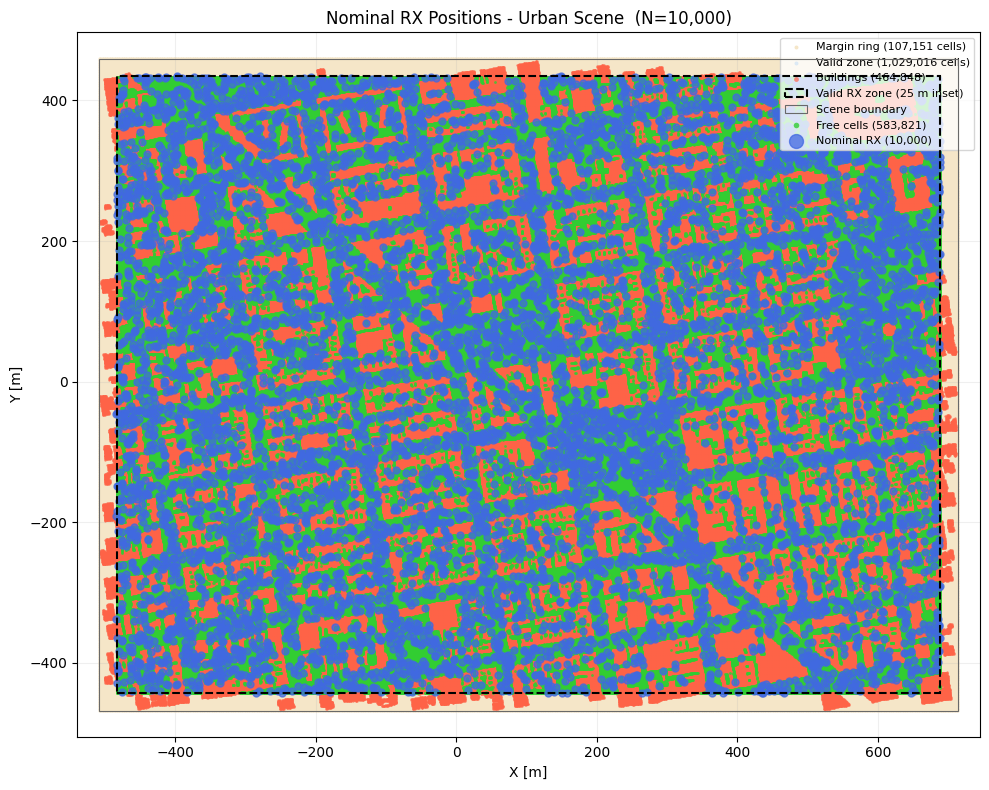

TX positions per elevation angle:
   10 deg  TX=(0.10 km, 492.40 km, 86.82 km)
   20 deg  TX=(0.10 km, 469.84 km, 171.01 km)
   30 deg  TX=(0.10 km, 433.01 km, 250.00 km)
   40 deg  TX=(0.10 km, 383.02 km, 321.39 km)
   50 deg  TX=(0.10 km, 321.39 km, 383.02 km)
   60 deg  TX=(0.10 km, 250.00 km, 433.01 km)
   70 deg  TX=(0.10 km, 171.01 km, 469.85 km)
   80 deg  TX=(0.10 km, 86.82 km, 492.40 km)
   90 deg  TX=(0.10 km, -0.00 km, 500.00 km)


In [17]:
# Visualise receiver placement
fig = plot_rx_positions(
    nominal_rx_positions = nominal_rx_positions,
    tx_pos               = None,
    free_xy              = free_xy,
    title                = f"Nominal RX Positions - Urban Scene  (N={len(nominal_rx_positions):,})",
    grid_meta=grid_meta
)
fig.savefig(f"{OUTPUT_DIR}/rx_positions_overview.png", dpi=120, bbox_inches='tight')
plt.show()

print("TX positions per elevation angle:")
for _elev in ELEVATION_ANGLES:
    _tp, _angles = tx_position_from_elevation(_elev, SLANT_DIST_M, SCENE_CENTER, radius=0, azimuth_deg=TX_AZIMUTH_DEG)
    print(f"  {_elev:3.0f} deg  TX=({_tp[0]/1e3:.2f} km, {_tp[1]/1e3:.2f} km, {_tp[2]/1e3:.2f} km)")

## 6 - Launch Simulations (Multi-GPU)

Two elevation angles are dispatched simultaneously, one per GPU, by
launching `run_elevation_sim.py` as subprocesses with different
`CUDA_VISIBLE_DEVICES` values.

```
GPU 0: elev=10  ──────────────────────► done
GPU 1: elev=30  ──────────────────────► done
                                              | wait for both
GPU 0: elev=60  ──────────────────────► done
GPU 1: elev=80  ──────────────────────► done
```

Set `NUM_GPUS = 1` in Section 3 to run all angles sequentially on GPU 0.

> **Non-blocking mode:** set `BLOCK_UNTIL_DONE = False` to start the
> subprocesses and continue editing. Call `wait_for_procs(active_procs)` later.

In [18]:
# ── Launch settings ─────────────────────────────────────────────────────────
# RESUME_FROM_CHECKPOINT: set this in the config cell above (cell 6).
# The launch cell reads it from the notebook namespace and passes it
# explicitly to each subprocess — no need to re-run the config cells.
BLOCK_UNTIL_DONE       = True  # False -> fire-and-forget
FORCE_FRESH_ANGLES     = []     # e.g. [10, 30] to force-restart specific angles
# RESUME_FROM_CHECKPOINT = False   # mirror of config-cell variable

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Determine which angles still need to be run
angles_needed = []
for _angle in ELEVATION_ANGLES:
    _res_file = os.path.join(OUTPUT_DIR, f"results_elev{int(_angle):03d}deg.pkl")
    if os.path.exists(_res_file) and RESUME_FROM_CHECKPOINT and not (_angle in FORCE_FRESH_ANGLES):
        print(f"  elev={_angle} deg  -> already complete, skipping")
    else:
        angles_needed.append(_angle)
print(f"\nAngles to run: {angles_needed}")


def launch_angle(angle, gpu_id, resume, force_fresh=False):
    """Launch run_elevation_sim.py for one elevation angle.

    Args:
        resume      : value of RESUME_FROM_CHECKPOINT from the notebook
        force_fresh : if True, passes --no-resume regardless of `resume`
    The subprocess always receives an explicit --resume or --no-resume flag
    so the notebook variable is the authoritative source of truth.
    """
    _env = dict(os.environ)
    _env["CUDA_VISIBLE_DEVICES"] = str(gpu_id)
    _cmd = [
        sys.executable,
        os.path.join(SCRIPT_DIR, "run_elevation_sim.py"),
        "--elevation", str(angle),
        "--gpu_id",    str(gpu_id),
        "--config",    CONFIG_FILE,
        "--rx_file",   RX_POSITIONS_FILE,
        "--output",    OUTPUT_DIR,
    ]
    # Section 3.6: if a real/synthetic-orbit satellite source produced a
    # waypoints file, pass the matching waypoint index instead of relying
    # on --elevation alone (TX position AND velocity then come from the
    # real SGP4 pass sample -- see run_elevation_sim.py).
    _wp_file = globals().get("WAYPOINTS_FILE")
    if _wp_file:
        _wp_idx_map = globals().get("WAYPOINT_INDEX_BY_ANGLE", {})
        _wp_idx = _wp_idx_map.get(angle)
        if _wp_idx is None:
            raise KeyError(
                f"No waypoint index found for angle={angle} in "
                f"WAYPOINT_INDEX_BY_ANGLE -- did ELEVATION_ANGLES change after "
                f"Section 3.6 ran? Re-run Section 3.6 to regenerate it."
            )
        _cmd += ["--waypoints_file", _wp_file, "--waypoint_index", str(_wp_idx)]
    if force_fresh or not resume:
        _cmd.append("--no-resume")   # explicit fresh start
        if force_fresh:
            print(f"  [FORCE FRESH] elev={angle}° — checkpoint ignored (force_fresh)")
        else:
            print(f"  [FRESH START] elev={angle}° — checkpoint ignored (RESUME_FROM_CHECKPOINT=False)")
    else:
        _cmd.append("--resume")      # explicit resume
    _log = open(os.path.join(OUTPUT_DIR, f"log_elev{int(angle):03d}deg.txt"), "w")
    _p   = subprocess.Popen(_cmd, env=_env, stdout=_log, stderr=subprocess.STDOUT)
    print(f"  Launched PID {_p.pid}  elev={angle}°  GPU={gpu_id}  resume={resume and not force_fresh}")
    return _p


def wait_for_procs(procs, poll_interval=30):
    t0 = time.perf_counter()
    while True:
        still = [p for p in procs if p.poll() is None]
        if not still:
            break
        print(f"  [{time.strftime('%H:%M:%S')}]  {len(still)} still running  "
              f"({(time.perf_counter()-t0)/3600:.2f} h)")
        time.sleep(poll_interval)
    print(f"  All done.  Total: {(time.perf_counter()-t0)/3600:.2f} h")


# Dispatch
active_procs = []

if NUM_GPUS >= 2:
    _pairs = [angles_needed[i:i+2] for i in range(0, len(angles_needed), 2)]
    for _pair in _pairs:
        _pair_procs = []
        for _gpu_id, _angle in enumerate(_pair):
            _p = launch_angle(_angle, _gpu_id,
                              resume=RESUME_FROM_CHECKPOINT,
                              force_fresh=(_angle in FORCE_FRESH_ANGLES))
            _pair_procs.append(_p)
            active_procs.append(_p)
        if BLOCK_UNTIL_DONE:
            print(f"\nWaiting for pair {[a for a in _pair]}...")
            wait_for_procs(_pair_procs)
else:
    for _angle in angles_needed:
        _p = launch_angle(_angle, gpu_id=0,
                          resume=RESUME_FROM_CHECKPOINT,
                          force_fresh=(_angle in FORCE_FRESH_ANGLES))
        active_procs.append(_p)
        if BLOCK_UNTIL_DONE:
            wait_for_procs([_p])

if not BLOCK_UNTIL_DONE:
    print(f"\n{len(active_procs)} process(es) running in background.")
    print("Run: wait_for_procs(active_procs) to block until complete.")


Angles to run: [10, 20, 30, 40, 50, 60, 70, 80, 90]
  Launched PID 3473944  elev=10°  GPU=0  resume=True
  Launched PID 3473945  elev=20°  GPU=1  resume=True

Waiting for pair [10, 20]...
  [10:36:14]  2 still running  (0.00 h)
  [10:36:44]  2 still running  (0.01 h)
  [10:37:14]  2 still running  (0.02 h)
  [10:37:44]  2 still running  (0.03 h)
  [10:38:14]  2 still running  (0.03 h)
  [10:38:44]  2 still running  (0.04 h)
  [10:39:14]  2 still running  (0.05 h)
  [10:39:44]  2 still running  (0.06 h)
  [10:40:14]  2 still running  (0.07 h)
  [10:40:44]  2 still running  (0.08 h)
  [10:41:14]  1 still running  (0.08 h)
  All done.  Total: 0.09 h
  Launched PID 3511536  elev=30°  GPU=0  resume=True
  Launched PID 3511537  elev=40°  GPU=1  resume=True

Waiting for pair [30, 40]...
  [10:41:44]  2 still running  (0.00 h)
  [10:42:14]  2 still running  (0.01 h)
  [10:42:44]  2 still running  (0.02 h)
  [10:43:14]  2 still running  (0.03 h)
  [10:43:44]  2 still running  (0.03 h)
  [10:44

In [ ]:
# Optional manual wait + status check
# wait_for_procs(active_procs)

simulation_status(OUTPUT_DIR, ELEVATION_ANGLES)